version                                 change  exp_lo  exp_hi  public  inside            status
     v1               baseline (emerging only)     NaN     NaN 0.11166   False           adopted
     v2                              flood GLM  0.1150  0.1300 0.11185   False           adopted
     v3        learn relativities on developed  0.1200  0.1550 0.12187    True           adopted
     v4   broker-book load x1.5 (new business)  0.1390  0.1420 0.14133    True           adopted
    v5a excess fix + row completeness, no load  0.1320  0.1380 0.13541    True        diagnostic
     v5           v5a + new-business load x1.3  0.1400  0.1450 0.14287    True           adopted
     v6            relative premium (contents)  0.1425  0.1450 0.14326    True           adopted
     v7                trend leverage restored  0.1426  0.1440 0.14336    True           adopted
     v8               new-business corrections  0.1433  0.1455 0.14077   False withdrawn (guard)
     v9       collinear groups

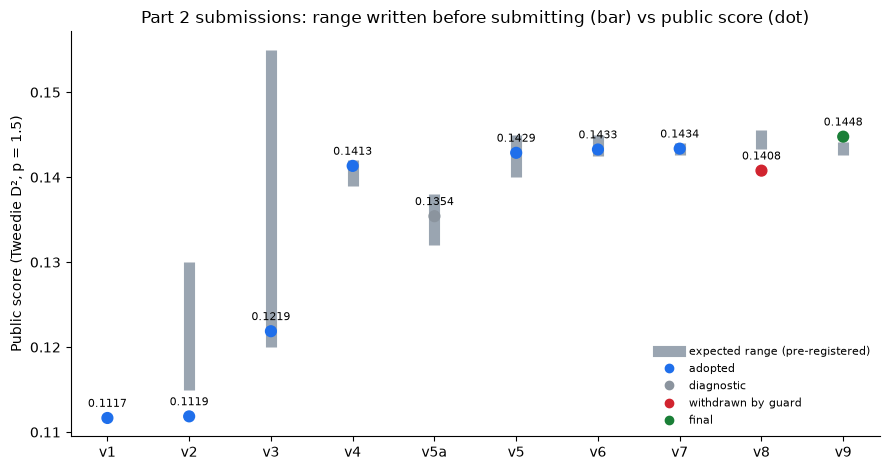

In [1]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
out = Path("results/report_figs"); out.mkdir(parents=True, exist_ok=True)

h = pd.DataFrame([
    ("v1", "baseline (emerging only)",              None,   None,   0.11166, "adopted"),
    ("v2", "flood GLM",                             0.115,  0.130,  0.11185, "adopted"),
    ("v3", "learn relativities on developed",       0.120,  0.155,  0.12187, "adopted"),
    ("v4", "broker-book load x1.5 (new business)",  0.139,  0.142,  0.14133, "adopted"),
    ("v5a","excess fix + row completeness, no load",0.132,  0.138,  0.13541, "diagnostic"),
    ("v5", "v5a + new-business load x1.3",          0.140,  0.145,  0.14287, "adopted"),
    ("v6", "relative premium (contents)",           0.1425, 0.1450, 0.14326, "adopted"),
    ("v7", "trend leverage restored",               0.1426, 0.1440, 0.14336, "adopted"),
    ("v8", "new-business corrections",              0.1433, 0.1455, 0.14077, "withdrawn (guard)"),
    ("v9", "collinear groups reduced (final)",      0.1426, 0.1442, 0.14477, "final"),
], columns=["version", "change", "exp_lo", "exp_hi", "public", "status"])
h["inside"] = (h.public >= h.exp_lo) & (h.public <= h.exp_hi)
h.to_csv(out / "submission_history_part2.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(h))
for i, r in h.iterrows():
    if pd.notna(r.exp_lo):
        ax.plot([i, i], [r.exp_lo, r.exp_hi], color="#9aa5b1", lw=8, solid_capstyle="butt", zorder=1)
col = h.status.map({"adopted": "#1f6feb", "diagnostic": "#8b949e", "withdrawn (guard)": "#d1242f", "final": "#1a7f37"})
ax.scatter(x, h.public, c=col, s=60, zorder=2)
for i, r in h.iterrows():
    ax.annotate(f"{r.public:.4f}", (i, r.public), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(h.version)
ax.set_ylabel("Public score (Tweedie D², p = 1.5)")
ax.set_title("Part 2 submissions: range written before submitting (bar) vs public score (dot)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color="#9aa5b1", lw=8, label="expected range (pre-registered)")] +
          [Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in
           [("adopted", "#1f6feb"), ("diagnostic", "#8b949e"), ("withdrawn by guard", "#d1242f"), ("final", "#1a7f37")]],
          loc="lower right", fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(out / "fig_submission_history.png", dpi=200)
print(h[["version", "change", "exp_lo", "exp_hi", "public", "inside", "status"]].to_string(index=False))
print("inside the written range:", int(h.inside.sum()), "of", int(h.exp_lo.notna().sum()))

13:19:42 motor: developed training table 979,968 rows
13:20:03 motor done
13:20:03 buildings: sum_insured x1000 entries divided by 1000: train 53, test 104
13:20:03 buildings: fire priced separately at 97.05 per exposure (developed)
13:20:04 buildings: own GLM for ['flood']; main GLM on the other perils
13:20:08 buildings: developed training table 707,726 rows
13:20:16 buildings done
13:20:16 contents: sum_insured x1000 entries divided by 1000: train 57, test 135
13:20:19 contents: developed training table 721,617 rows
13:20:41 contents done
     motor  buildings  contents
dec                            
1    0.784      0.563     0.869
2    1.185      0.929     0.622
3    1.163      0.812     1.117
4    1.132      0.958     1.027
5    1.215      0.988     0.784
6    1.222      0.860     1.023
7    1.010      0.690     0.859
8    1.199      0.676     0.947
9    1.095      0.867     0.897
10   0.918      1.014     0.975
rows: {'buildings': 14867, 'contents': 18732, 'motor': 25603}


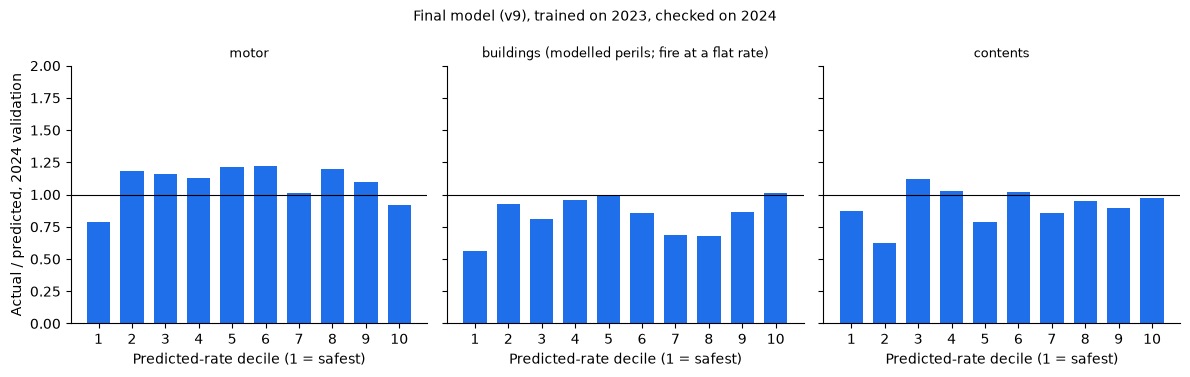

In [2]:
import os, sys, copy; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src.pipeline as P, src.target as T
from src.config import PART2
out = Path("results/report_figs"); out.mkdir(parents=True, exist_ok=True)

cfg = copy.deepcopy(PART2); T.AMOUNTS_NET, T.ROW_COMPLETENESS = True, True
claims = T.load_claims(cfg["data_dir"])
rows = []
for line in cfg["lines"]:
    d = P.build_line(line, cfg, claims)
    tr, va = d["tr"][d["tr"].year == 2023], d["tr"][d["tr"].year == 2024]
    rate, _ = P.predict_rate(line, cfg, tr, va, d["feats"])
    w = va.weight.to_numpy(); r = np.asarray(rate, float)
    act_mod = (va.target_modelled if "target_modelled" in va else va.target).to_numpy()
    act_all = (va.target_all if "target_all" in va else va.target).to_numpy()
    rows.append(pd.DataFrame({"line": line, "row_id": va.row_id.to_numpy(), "nb": va.new_business.to_numpy(), "w": w,
                              "rate": r, "pv_model": r * w, "act_model": act_mod,
                              "pv_all": (r + d.get("sep_rate", 0.0)) * w, "act_all": act_all}))
    P.log(f"{line} done")
v = pd.concat(rows, ignore_index=True)
v.to_csv(out / "valid2024_rows_v9.csv", index=False)

def deciles(g):
    g = g.sort_values("rate"); cw = g.w.cumsum() / g.w.sum()
    g = g.assign(dec=np.minimum((cw * 10).clip(upper=9.999).astype(int) + 1, 10))
    t = g.groupby("dec").agg(w=("w", "sum"), pv=("pv_model", "sum"), act=("act_model", "sum"))
    return t.assign(AE=t.act / t.pv)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
tabs = []
for ax, line in zip(axes, cfg["lines"]):
    t = deciles(v[v.line == line]); tabs.append(t.AE.rename(line))
    ax.bar(t.index, t.AE, color="#1f6feb", width=0.7)
    ax.axhline(1, color="black", lw=0.8); ax.set_ylim(0, 2)
    ax.set_title(line + (" (modelled perils; fire at a flat rate)" if line == "buildings" else ""), fontsize=9)
    ax.set_xlabel("Predicted-rate decile (1 = safest)"); ax.set_xticks(range(1, 11))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Actual / predicted, 2024 validation")
fig.suptitle("Final model (v9), trained on 2023, checked on 2024", fontsize=10)
fig.tight_layout(); fig.savefig(out / "fig_deciles_v9.png", dpi=200)
ae = pd.concat(tabs, axis=1); ae.to_csv(out / "deciles_v9.csv")
print(ae.round(3))
print("rows:", v.groupby("line").size().to_dict())

    motor  buildings  contents
1   0.787      0.571     0.853
2   1.146      0.855     0.641
3   1.142      0.987     1.094
4   1.194      0.898     1.046
5   1.199      0.920     0.807
6   1.197      0.793     1.003
7   1.053      0.727     0.842
8   1.165      0.847     0.964
9   1.145      0.766     0.892
10  0.878      1.013     0.978
matches the E27 decision values


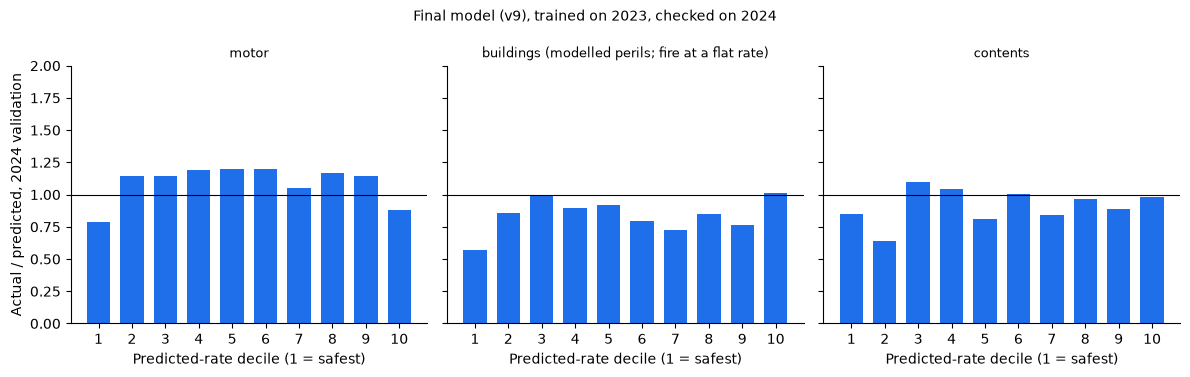

In [3]:
import os, sys; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.evaluate import evaluate
out = Path("results/report_figs")
v = pd.read_csv(out / "valid2024_rows_v9.csv")
lines = ["motor", "buildings", "contents"]
EXPECT = {"motor": (0.787, 0.878), "buildings": (0.571, 1.013), "contents": (0.853, 0.978)}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
tabs = []
for ax, line in zip(axes, lines):
    g = v[v.line == line]
    lf = evaluate(g.act_model, g.pv_model, g.w, show=False)["lift"]
    ae = lf["A/E"].reset_index(drop=True); ae.index = range(1, len(ae) + 1)
    assert abs(ae.iloc[0] - EXPECT[line][0]) < 0.001 and abs(ae.iloc[-1] - EXPECT[line][1]) < 0.001, (line, ae.iloc[0], ae.iloc[-1])
    tabs.append(ae.rename(line))
    ax.bar(ae.index, ae.values, color="#1f6feb", width=0.7)
    ax.axhline(1, color="black", lw=0.8); ax.set_ylim(0, 2)
    ax.set_title(line + (" (modelled perils; fire at a flat rate)" if line == "buildings" else ""), fontsize=9)
    ax.set_xlabel("Predicted-rate decile (1 = safest)"); ax.set_xticks(ae.index)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Actual / predicted, 2024 validation")
fig.suptitle("Final model (v9), trained on 2023, checked on 2024", fontsize=10)
fig.tight_layout(); fig.savefig(out / "fig_deciles_v9.png", dpi=200)
t = pd.concat(tabs, axis=1); t.to_csv(out / "deciles_v9.csv")
print(t.round(3)); print("matches the E27 decision values")

13:23:29 motor fitted
13:23:29 buildings: sum_insured x1000 entries divided by 1000: train 53, test 104
13:23:29 buildings: fire priced separately at 97.05 per exposure (developed)
13:23:29 buildings: own GLM for ['flood']; main GLM on the other perils
13:23:30 buildings fitted
13:23:30 contents: sum_insured x1000 entries divided by 1000: train 57, test 135
13:23:51 contents fitted
     line               feature  max/min
 contents            flood_zone     2.32
 contents           sum_insured     1.96
 contents           elevation_m     1.89
    motor             ncb_years     1.76
    motor        years_licensed     1.64
    motor       driver_age_band     1.59
buildings         energy_rating     1.12
buildings policyholder_age_band     1.11
buildings             soil_type     1.11
saved results/report_figs/fig_relativities_v9.png


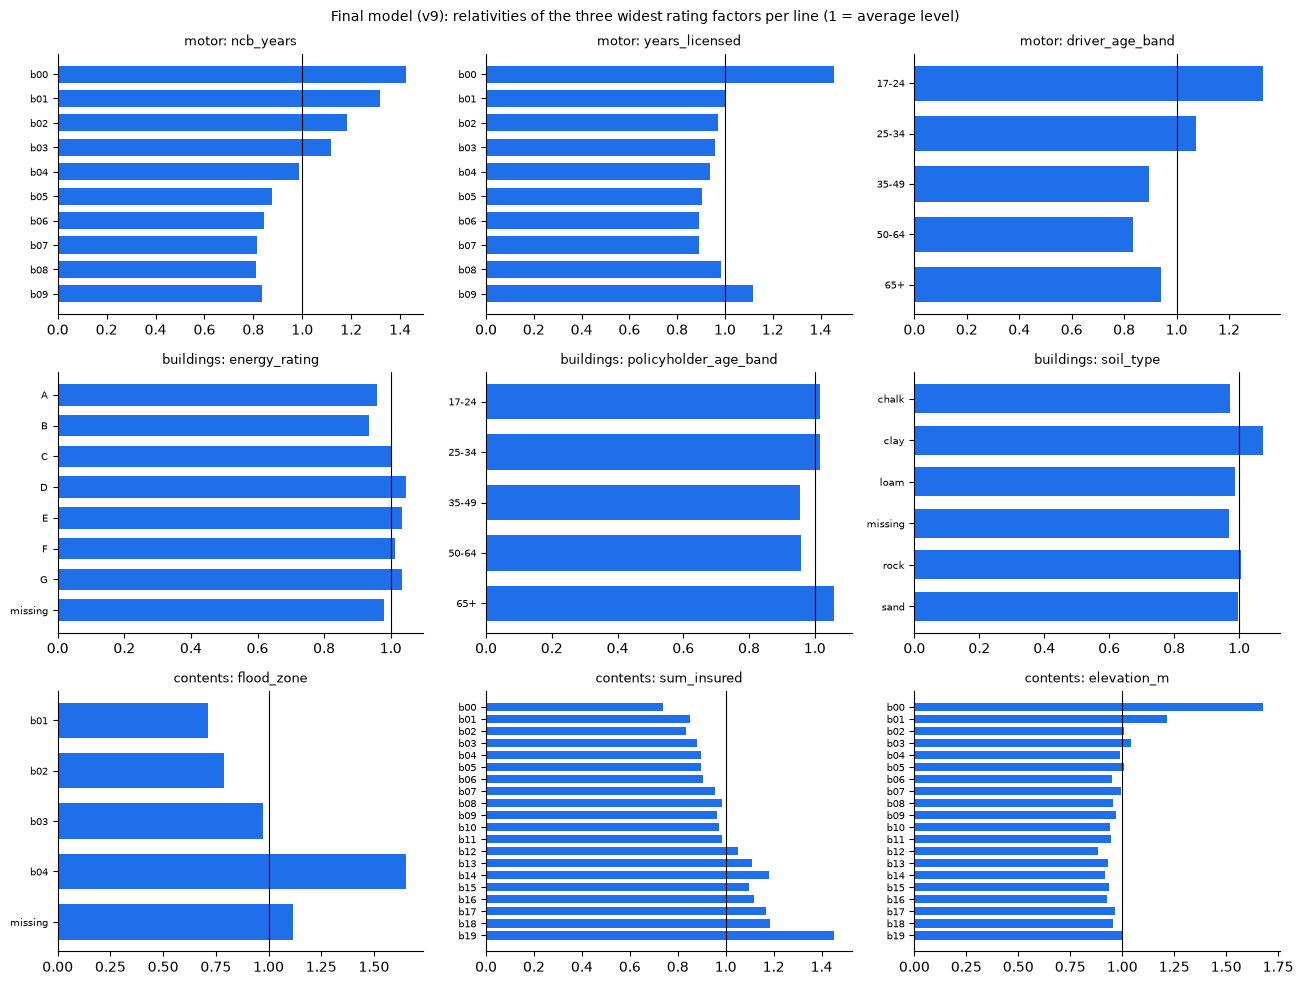

In [4]:
import os, sys, copy; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src.pipeline as P, src.target as T
from src.config import PART1, PART2
from src.glm import BandedTweedieGLM
out = Path("results/report_figs"); out.mkdir(parents=True, exist_ok=True)

cfg = copy.deepcopy(PART2); T.AMOUNTS_NET, T.ROW_COMPLETENESS = True, True
claims = T.load_claims(cfg["data_dir"])
rels = []
for line in cfg["lines"]:
    d = P.build_line(line, cfg, claims); tr, feats = d["tr"], d["feats"]           # final model: all emerging years
    mode = cfg.get("developed_training", {}).get(line)
    if mode:
        dev = P.developed_table(line, cfg); f = [c for c in feats if c in dev.columns]; kw = PART1["glm"][line]
        if mode == "developed":
            g = BandedTweedieGLM(**kw).fit(dev[f], dev.target / dev.weight, dev.weight)
        else:
            both = pd.concat([dev[f + ["target", "weight"]].assign(market="developed"),
                              tr[f + ["target", "weight"]].assign(market="emerging")], ignore_index=True)
            g = BandedTweedieGLM(**kw).fit(both[f + ["market"]], both.target / both.weight, both.weight)
    else:
        g = BandedTweedieGLM(**cfg["glm"][line]).fit(tr[feats], tr.target / tr.weight, tr.weight)
    r = g.relativities().assign(line=line, trained_on=mode or "emerging")
    rels.append(r[r.feature != "market"]); P.log(f"{line} fitted")
R = pd.concat(rels, ignore_index=True); R.to_csv(out / "relativities_v9.csv", index=False)

spread = R.groupby(["line", "feature"]).relativity.agg(lambda s: s.max() / s.min()).rename("max/min").reset_index()
top = spread.sort_values("max/min", ascending=False).groupby("line").head(3)
print(top.round(2).to_string(index=False))

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for i, line in enumerate(cfg["lines"]):
    for j, feat in enumerate(top[top.line == line].feature):
        ax = axes[i, j]; t = R[(R.line == line) & (R.feature == feat)]
        ax.barh(range(len(t)), t.relativity, color="#1f6feb", height=0.7)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(t.level, fontsize=7); ax.invert_yaxis()
        ax.axvline(1, color="black", lw=0.8)
        ax.set_title(f"{line}: {feat}", fontsize=9); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Final model (v9): relativities of the three widest rating factors per line (1 = average level)", fontsize=10)
fig.tight_layout(); fig.savefig(out / "fig_relativities_v9.png", dpi=200)
print("saved", out / "fig_relativities_v9.png")

In [5]:
import os, sys, copy; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import numpy as np, pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_tweedie_deviance
import src.pipeline as P, src.target as T
from src.config import PART2
from src.evaluate import evaluate

out = Path("results/bootstrap_murphy_v9"); out.mkdir(parents=True, exist_ok=True)
cfg = copy.deepcopy(PART2)
T.AMOUNTS_NET, T.ROW_COMPLETENESS = bool(cfg["amounts_net"]), bool(cfg["row_completeness"])
claims = T.load_claims(cfg["data_dir"])
parts = []
for line in cfg["lines"]:
    d = P.build_line(line, cfg, claims)
    tr0 = d["tr"].merge(d["p"][["row_id", "policy_id"]], on="row_id")
    vy, tys = cfg["folds"][0]
    tr, va = tr0[tr0.year.isin(tys)], tr0[tr0.year == vy]
    rate, _ = P.predict_rate(line, cfg, tr, va, d["feats"])
    rate = np.asarray(rate, float) + d.get("sep_rate", 0.0)
    parts.append(pd.DataFrame({"line": line, "row_id": va.row_id.to_numpy(), "policy_id": va.policy_id.astype(str).to_numpy(),
                               "nb": va.new_business.astype(bool).to_numpy(), "w": va.weight.to_numpy(),
                               "pv": rate * va.weight.to_numpy(),
                               "act": (va.target_all if "target_all" in va else va.target).to_numpy()}))
V = pd.concat(parts, ignore_index=True); V.to_csv(out / "valid2024_rows_v9.csv", index=False)
print(f"rows {len(V):,} | pooled D2 {evaluate(V.act, V.pv, V.w, show=False)['D2']:.4f}  (v7: 0.1081)\n")

def S(a, p): return mean_tweedie_deviance(a, np.maximum(p, 1e-9), power=1.5)
def murphy(df):
    a, p, w = df.act.to_numpy(), df.pv.to_numpy(), df.w.to_numpy()
    base = a.sum() / w.sum() * w; r = p / w
    iso = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(r, a / w, sample_weight=w)
    rec = np.maximum(iso.predict(r), 0) * w
    kstar = (a / np.sqrt(np.maximum(p, 1e-9))).sum() / np.sqrt(np.maximum(p, 1e-9)).sum()
    s, su, sr, sl = S(a, p), S(a, base), S(a, rec), S(a, p * kstar)
    return {"rows": len(a), "D2": 1 - s / su, "DSC (ranking)": (su - sr) / su, "MCB (miscalibration)": (s - sr) / su,
            "MCB removed by one level factor": (s - sl) / su, "k* (Tweedie-optimal level)": kstar, "A/E": a.sum() / p.sum()}
mrows = []
for line in ["ALL", "motor", "buildings", "contents"]:
    dl = V if line == "ALL" else V[V.line == line]
    for seg, ds in [("all rows", dl), ("new business", dl[dl.nb]), ("renewal", dl[~dl.nb])]:
        mrows.append({"line": line, "segment": seg, **murphy(ds)})
M = pd.DataFrame(mrows); M.to_csv(out / "murphy.csv", index=False)

TEST_ROWS = {("motor", True): 68823, ("motor", False): 21698, ("buildings", True): 39716,
             ("buildings", False): 12579, ("contents", True): 50441, ("contents", False): 15806}
rng, B, Q = np.random.default_rng(2026), 2000, 0.5
V["u"] = V.act / np.sqrt(V.pv.clip(lower=1e-9)); V["c"] = np.sqrt(V.pv.clip(lower=1e-9))
brows = []
for line in ["ALL", "motor", "buildings", "contents"]:
    dl = V if line == "ALL" else V[V.line == line]
    for seg, nbflag in [("all rows", None), ("new business", True), ("renewal", False)]:
        ds = dl if nbflag is None else dl[dl.nb == nbflag]
        g = ds.groupby("policy_id")[["u", "c"]].sum(); U, C = g.u.to_numpy(), g.c.to_numpy()
        ks = np.array([(lambda m: U[m].sum() / C[m].sum())(rng.random(len(U)) < Q) for _ in range(B)])
        lines_ = ["motor", "buildings", "contents"] if line == "ALL" else [line]
        flags = [True, False] if nbflag is None else [nbflag]
        n_test = sum(TEST_ROWS[(l, f)] for l in lines_ for f in flags)
        row = {"line": line, "segment": seg, "validation rows": len(ds), "k* (full fold)": U.sum() / C.sum(),
               "sd at half the fold": ks.std(), "95% at half the fold": f"{np.percentile(ks, 2.5):.3f}-{np.percentile(ks, 97.5):.3f}"}
        for f in (0.2, 0.3, 0.5):
            row[f"+-95% at public {int(f * 100)}%"] = 1.96 * ks.std() * np.sqrt(Q * len(ds) / (f * n_test))
        brows.append(row)
Bt = pd.DataFrame(brows); Bt.to_csv(out / "bootstrap_kstar.csv", index=False)

# side by side with v7 (notebook 29)
m7 = pd.read_csv("results/bootstrap_murphy/murphy.csv")
cmp = M.merge(m7, on=["line", "segment"], suffixes=("_v9", "_v7"))
cols = ["line", "segment"] + [f"{c}_{v}" for c in ["D2", "DSC (ranking)", "MCB (miscalibration)", "k* (Tweedie-optimal level)"] for v in ("v7", "v9")]
pd.set_option("display.width", 250)
print("=== Murphy: v7 vs v9 ===")
print(cmp[cols].round(4).to_string(index=False))
nb = Bt[(Bt.line == "ALL") & (Bt.segment == "new business")].iloc[0]
print("\nnew-business load 1.3: public-sampling 95% band "
      + ", ".join(f"{1.3 * (1 - nb[c]):.2f}-{1.3 * (1 + nb[c]):.2f} ({c.split('at ')[1]})" for c in Bt.columns if c.startswith("+-95%"))
      + "   (v7: 1.19-1.39 / 1.21-1.37 / 1.23-1.35)")
print(f"saved to {out}/")

13:24:21 buildings: sum_insured x1000 entries divided by 1000: train 53, test 104
13:24:21 buildings: fire priced separately at 97.05 per exposure (developed)
13:24:21 buildings: own GLM for ['flood']; main GLM on the other perils
13:24:29 contents: sum_insured x1000 entries divided by 1000: train 57, test 135
rows 59,202 | pooled D2 0.1084  (v7: 0.1081)

=== Murphy: v7 vs v9 ===
     line      segment   D2_v7   D2_v9  DSC (ranking)_v7  DSC (ranking)_v9  MCB (miscalibration)_v7  MCB (miscalibration)_v9  k* (Tweedie-optimal level)_v7  k* (Tweedie-optimal level)_v9
      ALL     all rows  0.1081  0.1084            0.1166            0.1167                   0.0085                   0.0083                         1.0067                         1.0058
      ALL new business  0.0652  0.0667            0.0901            0.0889                   0.0250                   0.0222                         1.0190                         1.0152
      ALL      renewal  0.1136  0.1137            0.1240

In [6]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
txt = """### Murphy decomposition and bootstrap re-run on v9 (Oct 25, notebook 31) — results/bootstrap_murphy_v9/
- Expected before running: pooled D2 0.108-0.109; DSC, MCB, k* and the new-business band within +-0.002 of v7. **Held.**
- Pooled D2 0.1084 (v7 0.1081) = DSC 0.1167 - MCB 0.0083; k* 1.0058. New business D2 0.0652 -> 0.0667, MCB 0.0250 -> 0.0222
  (motor new business 0.0038 -> 0.0063); contents identical (unchanged by E27).
- New-business load 1.3, public-sampling 95% band: 1.20-1.40 (public 20%), 1.22-1.38 (30%), 1.24-1.36 (50%); v7 1.19-1.39 / 1.21-1.37 /
  1.23-1.35. Report figures now on v9: results/report_figs/ (submission history, deciles, relativities).
"""
p = Path("DECISIONS.md"); d = p.read_text(encoding="utf-8")
a = "## Assumptions register"; assert d.count(a) == 1 and "re-run on v9" not in d
p.write_text(d.replace(a, txt + "\n" + a), encoding="utf-8"); print("recorded")

recorded


13:28:47 motor fitted
13:28:47 buildings: sum_insured x1000 entries divided by 1000: train 53, test 104
13:28:48 buildings: fire priced separately at 97.05 per exposure (developed)
13:28:48 buildings: own GLM for ['flood']; main GLM on the other perils
13:28:56 buildings fitted
13:28:56 contents: sum_insured x1000 entries divided by 1000: train 57, test 135
13:29:18 contents fitted
motor (main GLM) widest: {'ncb_years': 1.76, 'years_licensed': 1.64, 'driver_age_band': 1.59}
buildings (flood GLM) widest: {'flood_zone': 6.14, 'elevation_m*flood_zone': 3.35, 'elevation_m': 2.75}
contents (main GLM) widest: {'flood_zone': 2.32, 'sum_insured': 1.96, 'elevation_m': 1.89}
saved results/report_figs/fig_relativities_v9.png


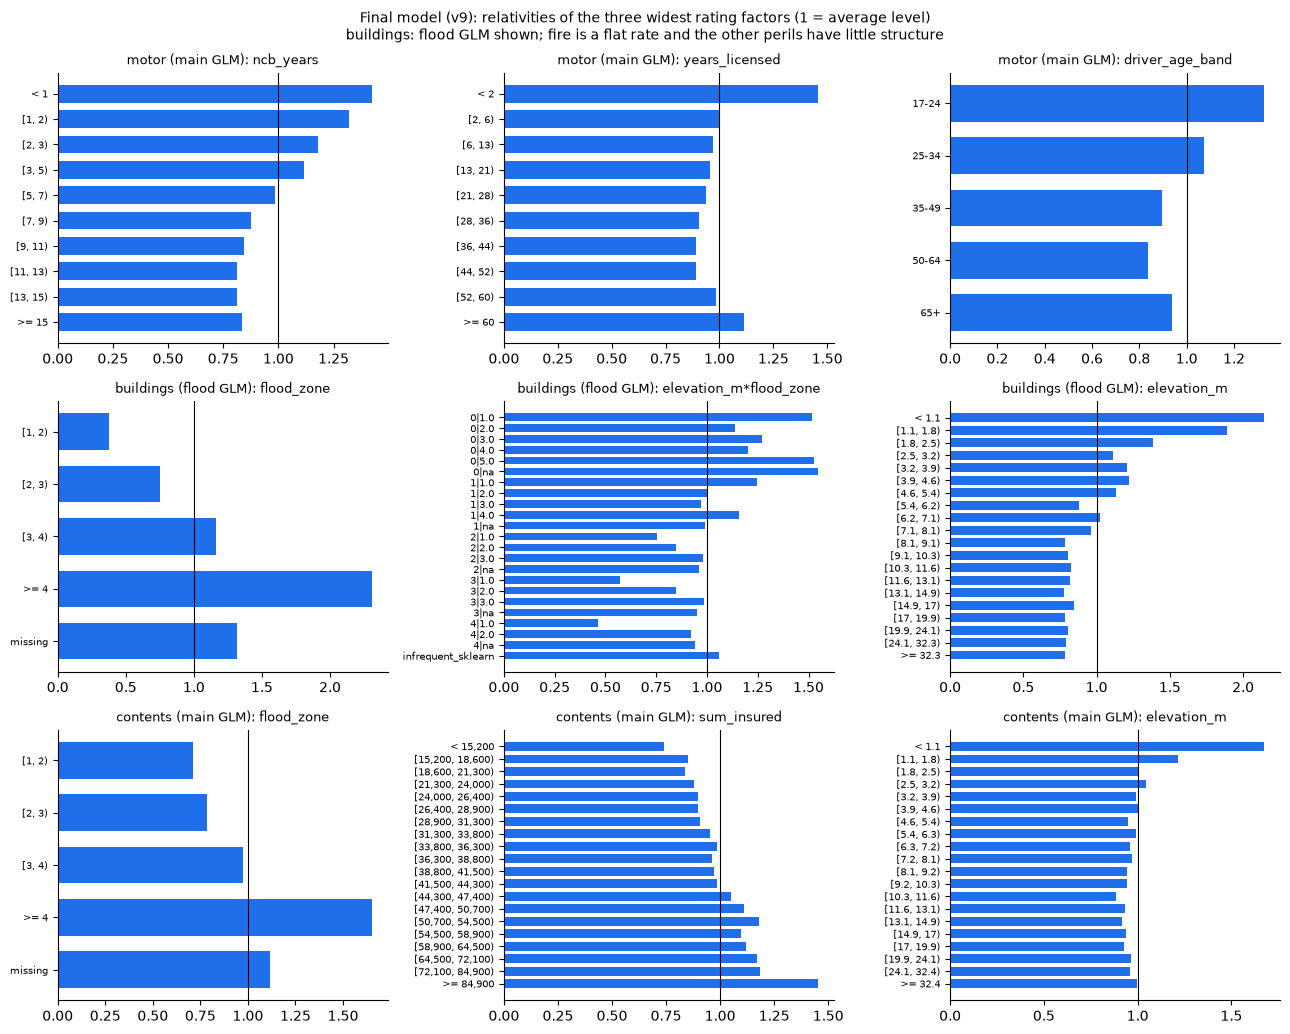

In [7]:
import os, sys, copy; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src.pipeline as P, src.target as T
from src.config import PART1, PART2
from src.glm import BandedTweedieGLM
out = Path("results/report_figs")

cfg = copy.deepcopy(PART2); T.AMOUNTS_NET, T.ROW_COMPLETENESS = True, True
claims = T.load_claims(cfg["data_dir"])

def fmt(x): return f"{x:,.0f}" if abs(x) >= 100 else f"{x:.3g}"
def labelled(g, model_name, line):
    r = g.relativities(); r = r[r.feature != "market"].copy()
    def lab(feat, lev):
        if feat in g.edges_ and lev.startswith("b") and lev[1:].isdigit():
            e, k = g.edges_[feat], int(lev[1:])
            if len(e) == 0: return "all"
            if k == 0: return f"< {fmt(e[0])}"
            if k >= len(e): return f">= {fmt(e[-1])}"
            return f"[{fmt(e[k - 1])}, {fmt(e[k])})"
        return lev
    r["label"] = [lab(f, l) for f, l in zip(r.feature, r.level)]
    return r.assign(line=line, model=model_name)

rels = []
for line in cfg["lines"]:
    d = P.build_line(line, cfg, claims); tr, feats = d["tr"], d["feats"]
    mode = cfg.get("developed_training", {}).get(line)
    if mode:
        dev = P.developed_table(line, cfg); f = [c for c in feats if c in dev.columns]; kw = PART1["glm"][line]
        if mode == "developed":
            g = BandedTweedieGLM(**kw).fit(dev[f], dev.target / dev.weight, dev.weight)
        else:
            both = pd.concat([dev[f + ["target", "weight"]].assign(market="developed"),
                              tr[f + ["target", "weight"]].assign(market="emerging")], ignore_index=True)
            g = BandedTweedieGLM(**kw).fit(both[f + ["market"]], both.target / both.weight, both.weight)
    else:
        g = BandedTweedieGLM(**cfg["glm"][line]).fit(tr[feats], tr.target / tr.weight, tr.weight)
    rels.append(labelled(g, "main GLM", line))
    for spec in cfg.get("peril_models", {}).get(line, []):              # buildings flood GLM, as in predict_rate
        col = f"target_{spec['peril']}"; kwp = dict(cfg["glm"][line], alpha=spec["alpha"])
        dev = P.developed_table(line, cfg)
        raw = [c for c in spec["features"] if c in tr.columns and c in dev.columns]
        prs = [tuple(x) for x in spec.get("pairs", [])]
        both = pd.concat([dev[raw + [col, "weight"]].assign(market="developed"),
                          tr[raw + [col, "weight"]].assign(market="emerging")], ignore_index=True)
        both, _, _ = P.add_pairs(both, [both, tr[raw + [col, "weight"]], tr[raw]], prs)
        fp = raw + [P.pair_name(*x) for x in prs]
        gp = BandedTweedieGLM(**kwp).fit(both[fp + ["market"]], both[col] / both.weight, both.weight)
        rels.append(labelled(gp, f"{spec['peril']} GLM", line))
    P.log(f"{line} fitted")
R = pd.concat(rels, ignore_index=True); R.to_csv(out / "relativities_v9_labelled.csv", index=False)

panels = {"motor": ("motor", "main GLM"), "buildings": ("buildings", "flood GLM"), "contents": ("contents", "main GLM")}
fig, axes = plt.subplots(3, 3, figsize=(13, 10.5))
for i, (name, (line, model)) in enumerate(panels.items()):
    sub = R[(R.line == line) & (R.model == model)]
    sp = sub.groupby("feature").relativity.agg(lambda s: s.max() / s.min()).sort_values(ascending=False)
    print(f"{line} ({model}) widest:", sp.head(3).round(2).to_dict())
    for j, feat in enumerate(sp.index[:3]):
        ax = axes[i, j]; t = sub[sub.feature == feat]
        ax.barh(range(len(t)), t.relativity, color="#1f6feb", height=0.7)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(t.label, fontsize=7); ax.invert_yaxis()
        ax.axvline(1, color="black", lw=0.8)
        ax.set_title(f"{line} ({model}): {feat}", fontsize=9); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Final model (v9): relativities of the three widest rating factors (1 = average level)\n"
             "buildings: flood GLM shown; fire is a flat rate and the other perils have little structure", fontsize=10)
fig.tight_layout(); fig.savefig(out / "fig_relativities_v9.png", dpi=200)
print("saved", out / "fig_relativities_v9.png")

In [1]:
import os, shutil; from pathlib import Path; os.chdir(Path.home()/"IAA")
src, dst = Path("results/report_figs"), Path("docs/figs"); dst.mkdir(parents=True, exist_ok=True)
files = ["fig_submission_history.png", "fig_deciles_v9.png", "fig_relativities_v9.png",
         "submission_history_part2.csv", "deciles_v9.csv"]
for f in files:
    assert (src / f).exists(), f
    shutil.copy2(src / f, dst / f)
print("copied:", files)

old = "Checked independently in a spreadsheet: `docs/krista_office_premium_check.md`."
new = "Independent spreadsheet check by Krista: in progress (Oct 26); the result will be recorded in `docs/krista_office_premium_check.md`."
for p in [Path("docs/office_premium_reference_v9.md"), Path("docs/office_premium_reference_v7.md")]:
    s = p.read_text(encoding="utf-8")
    if old in s:
        p.write_text(s.replace(old, new), encoding="utf-8"); print("fixed", p)

copied: ['fig_submission_history.png', 'fig_deciles_v9.png', 'fig_relativities_v9.png', 'submission_history_part2.csv', 'deciles_v9.csv']
fixed docs/office_premium_reference_v9.md
fixed docs/office_premium_reference_v7.md


motor (main GLM): {'ncb_years': 1.76, 'years_licensed': 1.64, 'driver_age_band': 1.59}
buildings (flood GLM): {'flood_zone': 6.14, 'elevation_m': 2.75, 'distance_to_river_km': 1.84}
contents (main GLM): {'flood_zone': 2.32, 'sum_insured': 1.96, 'elevation_m': 1.89}
saved


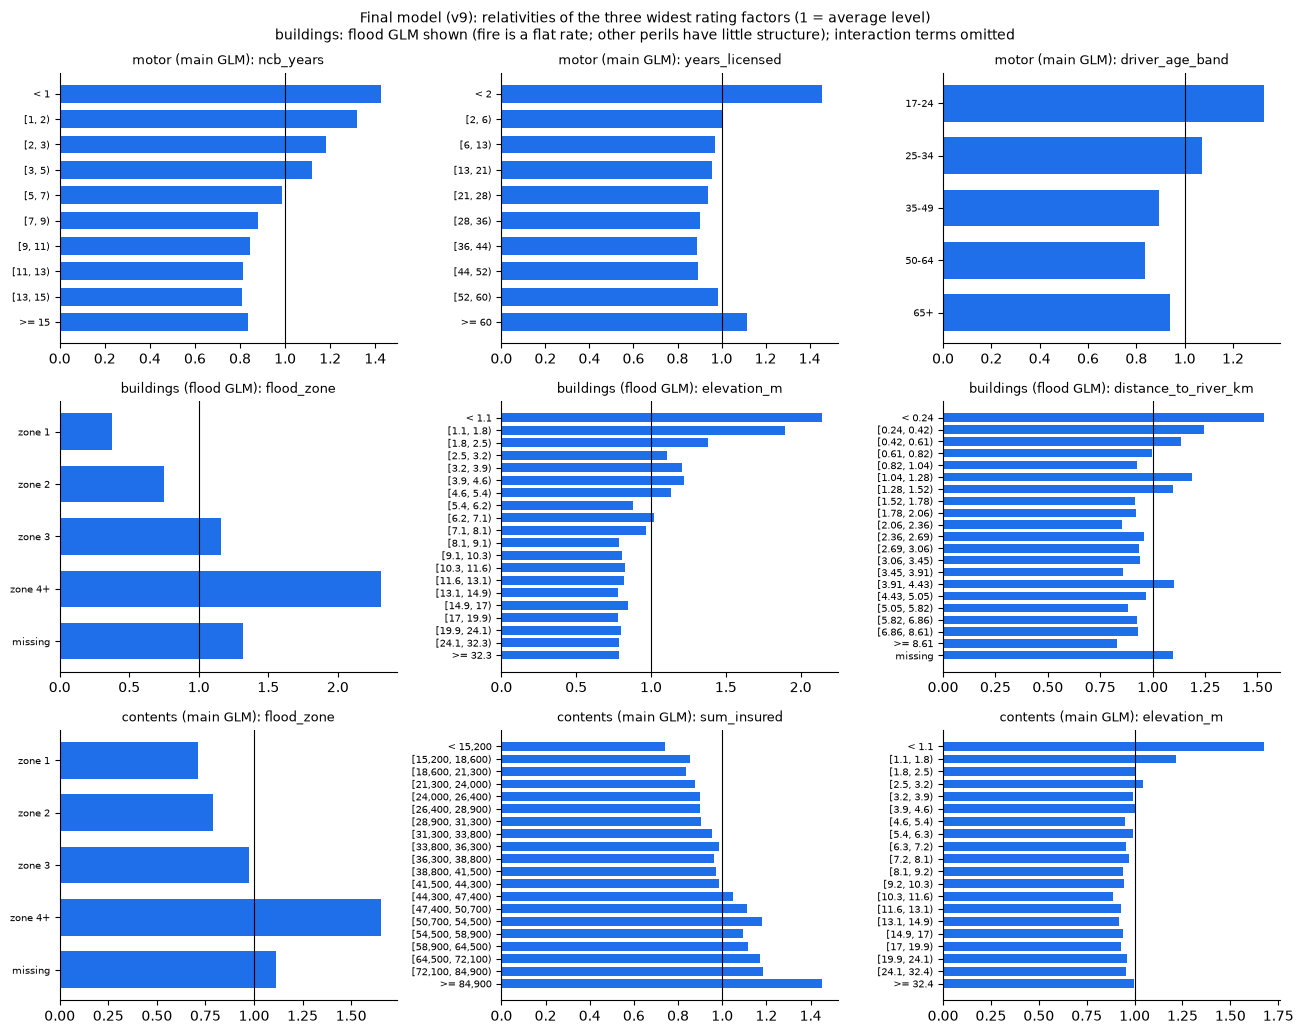

In [2]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
import pandas as pd, matplotlib.pyplot as plt
R = pd.read_csv("results/report_figs/relativities_v9_labelled.csv")
R = R[~R.feature.str.contains(r"\*")].copy()                       # drop pair terms (unreadable codes)
zone = {"[1, 2)": "zone 1", "[2, 3)": "zone 2", "[3, 4)": "zone 3", ">= 4": "zone 4+", "< 1": "zone 0"}
m = R.feature == "flood_zone"; R.loc[m, "label"] = R.loc[m, "label"].map(lambda s: zone.get(s, s))

panels = [("motor", "main GLM"), ("buildings", "flood GLM"), ("contents", "main GLM")]
fig, axes = plt.subplots(3, 3, figsize=(13, 10.5))
for i, (line, model) in enumerate(panels):
    sub = R[(R.line == line) & (R.model == model)]
    sp = sub.groupby("feature").relativity.agg(lambda s: s.max() / s.min()).sort_values(ascending=False)
    print(f"{line} ({model}):", sp.head(3).round(2).to_dict())
    for j, feat in enumerate(sp.index[:3]):
        ax = axes[i, j]; t = sub[sub.feature == feat]
        ax.barh(range(len(t)), t.relativity, color="#1f6feb", height=0.7)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(t.label, fontsize=7); ax.invert_yaxis()
        ax.axvline(1, color="black", lw=0.8)
        ax.set_title(f"{line} ({model}): {feat}", fontsize=9); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Final model (v9): relativities of the three widest rating factors (1 = average level)\n"
             "buildings: flood GLM shown (fire is a flat rate; other perils have little structure); interaction terms omitted", fontsize=10)
fig.tight_layout()
for p in ["results/report_figs/fig_relativities_v9.png", "docs/figs/fig_relativities_v9.png"]:
    fig.savefig(p, dpi=200)
print("saved")

motor (main GLM): {'ncb_years': 1.76, 'years_licensed': 1.64, 'driver_age_band': 1.59}
buildings (flood GLM): {'flood_zone': 6.14, 'elevation_m': 2.75, 'distance_to_river_km': 1.84}
contents (main GLM): {'flood_zone': 2.32, 'sum_insured': 1.96, 'elevation_m': 1.89}
saved


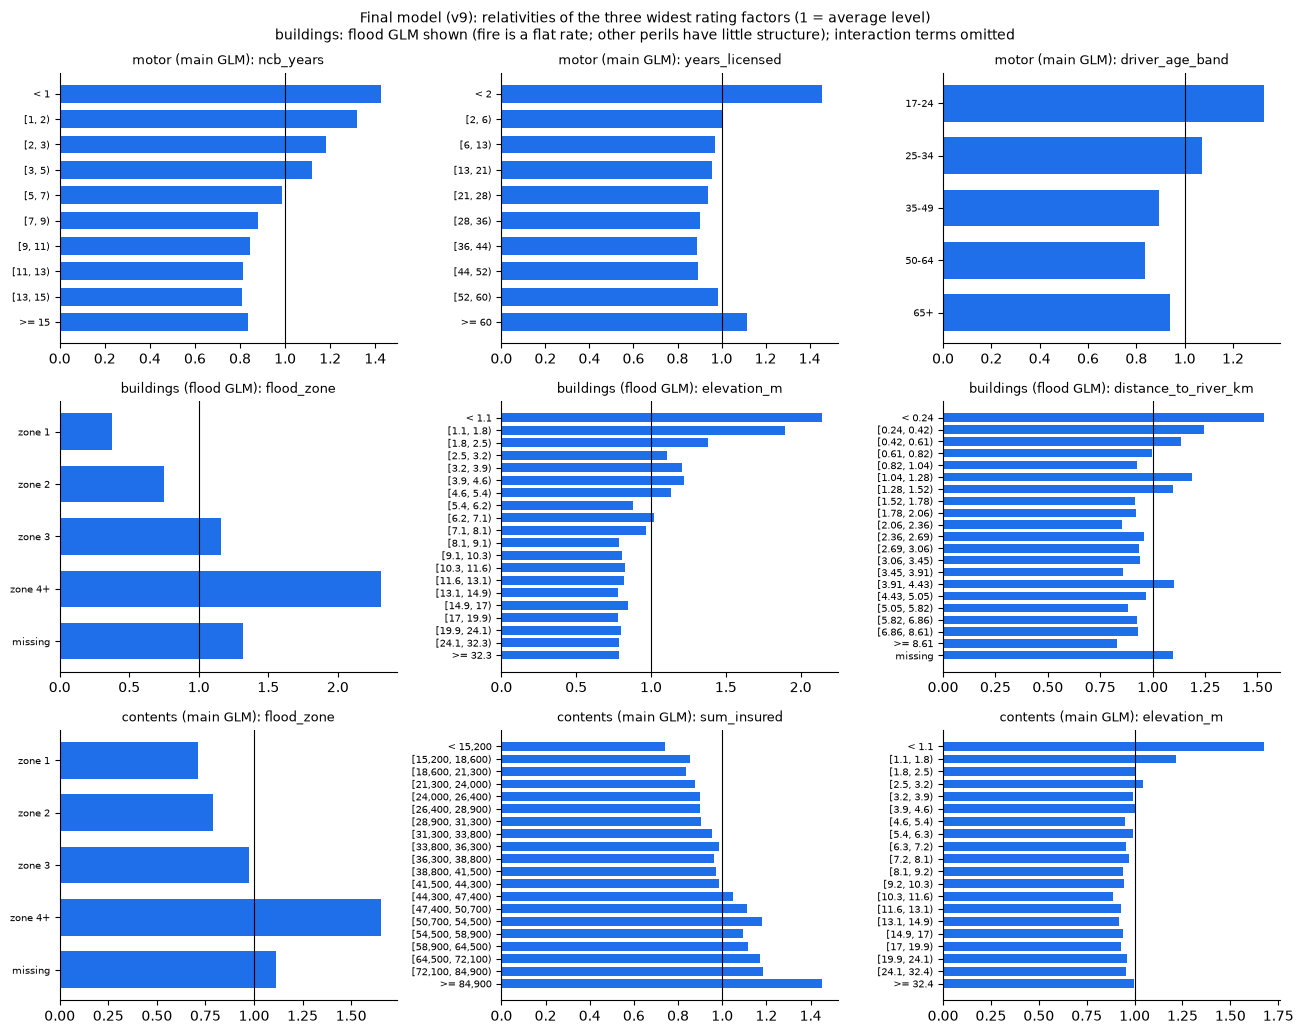

In [1]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
import pandas as pd, matplotlib.pyplot as plt
R = pd.read_csv("results/report_figs/relativities_v9_labelled.csv")
R = R[~R.feature.str.contains(r"\*")].copy()                       # drop pair terms (unreadable codes)
zone = {"[1, 2)": "zone 1", "[2, 3)": "zone 2", "[3, 4)": "zone 3", ">= 4": "zone 4+", "< 1": "zone 0"}
m = R.feature == "flood_zone"; R.loc[m, "label"] = R.loc[m, "label"].map(lambda s: zone.get(s, s))

panels = [("motor", "main GLM"), ("buildings", "flood GLM"), ("contents", "main GLM")]
fig, axes = plt.subplots(3, 3, figsize=(13, 10.5))
for i, (line, model) in enumerate(panels):
    sub = R[(R.line == line) & (R.model == model)]
    sp = sub.groupby("feature").relativity.agg(lambda s: s.max() / s.min()).sort_values(ascending=False)
    print(f"{line} ({model}):", sp.head(3).round(2).to_dict())
    for j, feat in enumerate(sp.index[:3]):
        ax = axes[i, j]; t = sub[sub.feature == feat]
        ax.barh(range(len(t)), t.relativity, color="#1f6feb", height=0.7)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(t.label, fontsize=7); ax.invert_yaxis()
        ax.axvline(1, color="black", lw=0.8)
        ax.set_title(f"{line} ({model}): {feat}", fontsize=9); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Final model (v9): relativities of the three widest rating factors (1 = average level)\n"
             "buildings: flood GLM shown (fire is a flat rate; other perils have little structure); interaction terms omitted", fontsize=10)
fig.tight_layout()
for p in ["results/report_figs/fig_relativities_v9.png", "docs/figs/fig_relativities_v9.png"]:
    fig.savefig(p, dpi=200)
print("saved")

In [2]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
txt = """

### Part 2 results (Oct 26, final v9) — what happened to each assumption in the emerging market
Result: **held** (still true on Part 2 data) · **changed** (adapted to the new market) · **wrong -> fixed** (wrong since Part 1, found in
Part 2) · **borrowed** (not testable on two emerging years; taken from the developed market) · **new** (needed only in Part 2).
Source: **doc** (competition documents) · **data** (tested on data) · **LB** (size calibrated on diagnostic submissions, disclosed) ·
**dev** (borrowed from the developed market).

| Assumption | Part 1 | Part 2 | Result | Source | Evidence |
|---|---|---|---|---|---|
| Claim amounts and excess | excess deducted on every peril | amounts are already net of excess; not deducted again | **wrong -> fixed** | doc, data | Data dictionary (also in Part 1's); paid = incurred on closed claims 100%; target x1.20 / 1.05 / 1.19; Part 1 late submission private -0.0020 [AI 107] |
| Trend with an excess | trend ground-up, excess fixed | same, restored for net amounts (excess added back before the trend) | **wrong -> fixed** | data | Lost in the Oct 24 fix; level x1.017 / 1.006 / 1.010; v7 [AI 112] |
| Recoveries | subtracted once | subtracted once | held | data | Fixed share of incurred (0.8 / 0.3); never above incurred |
| Claim linkage | row_id, both ends inclusive | same; 0.3-0.5% of claims before the policy's first row excluded | held | data | Independent target audit [AI 114] |
| Declined claims | excluded | excluded | held | doc, data | Cost concentration in declined rows noted for the report [AI 114] |
| Exposure | recomputed from dates where inconsistent | same | held | data | About 0.5% of rows wrong, inflating total exposure by about 40%; test rows consistent; 2024 rows end at the valuation date |
| sum_insured entry error | — | x1000 entries divided by 1000 | **new** | data | Five checks fixed before looking (same policy, premium, gaps, digits, property) [AI 93] |
| Completeness (IBNR) | Lynden-Bell by peril, yearly | each row's own period (E22) | **wrong -> fixed** | data | Late-starting new-business rows were less complete (motor 2024 0.777 vs 0.839); motor NB A/E 0.94 -> 1.00 [AI 109] |
| Severity trends | estimated on 2021-24 | borrowed from the developed market | **borrowed** | dev | Two emerging years cannot separate trend from noise; sensitivity only |
| BI reform factor | 0.83 on 2021-22 | none | changed | doc | A developed-market legal change |
| Large losses, motor | cap 500k + Pareto loading (alpha from the data) | cap 500k + Pareto, alpha 2.05 borrowed, frequency from emerging | **borrowed** | dev | Too few large claims to fit a tail |
| Large losses, buildings fire | in the GLM, observed loading | flat developed rate 97.05 per exposure | changed | data, dev | 2023 regional fire cluster (49 vs 21 claims); depth-3 tree found it [AI 98] |
| Buildings flood | five flood-geography pairs in the GLM | own flood GLM on combined data | changed | data | E12 re-judged under the tail rule without the flat fire part [AI 102] |
| Where relativities are learned | the same market | motor: developed; contents: developed + emerging; buildings: emerging (+ flood combined); level always from emerging | changed | data | E17: validation D2 0.0806 -> 0.1096, public 0.11185 -> 0.12187 [AI 103] |
| New-business relativity | from data | emerging values kept | held | data | Within 2 SE of the developed market in every line (Rule 1) |
| Broker book in the 2025 test | — | new-business load x1.3 | **new** | doc, LB | Competition text (broker book, 76% new business); not identifiable in the data; size from diagnostic submissions (x1.5 in v4, x1.3 after the excess fix); public-sampling band 1.22-1.38 [AI 106] |
| Claim history | 1 and 2 years | 1 year only | changed | data | A 2-year window is never observable from a 2023 start; the test broker book has no history |
| Weather for 2025 | address average | address average | held | data | Actual 2025 weather as a diagnostic: public +0.0006, not the cause of the gap |
| written_premium | contents, by start month | contents, annual premium relative to the year | held | data | E23 +0.0014 D2; still circular |
| Feature removals | stability and add/drop tests | + occupation (free text); + 7 collinear variables in motor and buildings (E27) | changed | data | E27: climate first component 79%, vehicle 94%; contents fails its lowest decile; v9 0.14477 [AI 115] |
| Model per line | motor freq x sev GLMs; buildings GLM; contents GBM | one Tweedie GLM per line (+ buildings flood GLM) | changed | data | E14 (motor freq x sev) not adopted; GBMs and black boxes fail the rule (E9-P2, E9-P2b) |
| Ridge strength | grid on two validation years | buildings alpha 10 (CV inside the training year); motor and contents keep Part 1 settings on developed / combined data | changed | data | Offset-correction ridge scale error found and re-run [AI 113] |
| Severity independent of frequency | verified in motor | not re-tested | **borrowed** | dev | One emerging fold; severity unpredictable within a peril (E13) |
| Validation design | two out-of-time folds | one fold (2024 on 2023) | changed | data | 6 of 9 public scores inside the range written before submitting |
| Tail rule for buildings | all perils | modelled perils only (flat fire excluded) | **new** | data | Team decision Oct 24 [AI 102] |
| Decision rules | fixed before results | unchanged, plus a guard for every submission | **new** | — | v8 withdrawn by its guard (public 0.14077); v9 kept by its guard |
"""
p = Path("DECISIONS.md"); d = p.read_text(encoding="utf-8")
old_h = "## Assumptions register (status as of Oct 22, after E1–E11)"
new_h = "## Assumptions register (status as of Oct 22, after E1–E11; Part 2 results at the end, Oct 26)"
assert d.count(old_h) == 1 and "### Part 2 results (Oct 26" not in d
d = d.replace(old_h, new_h).rstrip("\n") + txt
p.write_text(d, encoding="utf-8"); print("Part 2 column added")

Part 2 column added


In [3]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
upd = """## Part 2 update (Oct 26) — this section wins where it differs from the Part 1 draft below

**Thesis (unchanged):** *AI writes the code; actuaries own the assumptions.* **Part 2 addition:** the largest score gains came from
assumptions, not model capacity: where relativities are learned (E17, 0.112 -> 0.122), the broker-book load (-> 0.141), the claim-amount
definition (-> 0.143). The black box did not beat our GLM in either market; the Oct 22 prediction ("the black box scores higher") was
wrong again.

**Results:** Part 1 final v12 (public 0.12336, private 0.13099). Part 2 final v9 (public 0.14477), rebuilt exactly from a fresh clone
(max difference 0).

**Judging weights:** pricing performance and adaptation 40% (private scores + modelling choices, adaptation, data quality, uncertainty),
effective AI use 25%, trust / validation / guardrails 20%, communication 15%. Task requirement: office premium for each of the 20
reference policies. Rules 2.9: reproducible code (done).

| # | Section | Content | Pages | Criterion | Draft |
|---|---|---|---|---|---|
| 0 | Summary | task, thesis, results, timeline | 1/2 | communication | Krista |
| 1 | Data and target | Part 1 issues; Part 2: excess double deduction (back to Part 1, private -0.0020), sum_insured x1000, row completeness (E22), independent audits (AI 108, 114) | 3/4 | pricing (data quality) | Woojin |
| 2 | Assumption ledger | DECISIONS "Part 2 results" table: held / changed / wrong -> fixed / borrowed / new, with source class (doc / data / LB / dev) | 3/4 | pricing (uncertainty) | Woojin |
| 3 | Model and adaptation | GLMs, developed relativities + emerging level, flat fire, flood GLM, broker-book load, E27 simplification (v9); black-box table Part 1 + Part 2; figures: relativities, deciles | 1 | pricing (modelling, adaptation) | Woojin |
| 4 | Office premium, 20 policies | formula, expense assumptions, the 20-row table (2-6x current premium), six open judgements; Krista's independent spreadsheet check | 1/2 | pricing; task requirement | Krista checks, Woojin writes |
| 5 | Validation and guardrails | rules fixed before results; submission history (6 of 9 inside the written range; v8 withdrawn by its guard; v9 above); Murphy decomposition and new-business band; reproducibility; 51 tests | 1/2 | trust | Woojin, Krista edits |
| 6 | How we used AI | roles (builder AI -> reviewer AI -> team); log counts; questions that caught errors (15, from the question log); one story in depth (the excess); quoted prompts | 3/4 | AI use | Krista drafts |
| 7 | Limitations and lessons | broker-book size from the leaderboard, borrowed severity trends, IBNER not modelled, buildings safest decile over-priced; no claim-file reconciliation | 1/4 | pricing (uncertainty) | both |

**AI log counts (Oct 26, entries 1-116, 113 in table form):** H 42 (team questioned), E 37 (AI errors), A 34 (AI proposed, team verified).
Part 2 (93-116): H 10, E 11, A 3 — AI proposed less, the team questioned more and caught more AI errors.

**Figures (docs/figs):** fig_submission_history.png (section 5), fig_deciles_v9.png (3), fig_relativities_v9.png (3); Part 1 figures as
planned below. Still to make: assumption-ledger summary graphic or table (2), AI roles diagram (6).

**Video (5 min):** keep the Part 1 plan; the last minute becomes "Part 2: assumptions moved the score".

---

"""
p = Path("docs/REPORT_OUTLINE.md"); s = p.read_text(encoding="utf-8")
anchor = "## 0. Summary"
assert s.count(anchor) == 1 and "## Part 2 update (Oct 26)" not in s
p.write_text(s.replace(anchor, upd + anchor), encoding="utf-8"); print("outline updated")

outline updated


In [4]:
import os, sys, copy; from pathlib import Path; os.chdir(Path.home()/"IAA"); sys.path.insert(0, str(Path.home()/"IAA"))
import numpy as np, pandas as pd
import src.pipeline as P, src.target as T
from src.config import PART2
out = Path("results/office_premium_v9")

# (1) decompose the 20-row multiple: office / current = (risk / current) x (office / risk)
r = pd.read_csv(out / "reference_20.csv")
r["expected_LR"] = r.risk_annual / r.current_premium            # risk part
r["expense_mult"] = r.office_annual / r.risk_annual             # expense, commission, tax, profit part
r["office/current"] = r.office_annual / r.current_premium
r["driver"] = np.where(r.expected_LR > 1, "risk alone exceeds current", "expenses make it short")
print(r[["row_id", "line", "channel", "risk_annual", "current_premium", "expected_LR", "expense_mult", "office/current", "driver"]]
      .round(2).to_string(index=False))
print("\n", r.groupby(["line", "driver"]).size().unstack(fill_value=0))
r.to_csv(out / "reference_20_decomposed.csv", index=False)

# (2) portfolio loss ratio in the emerging training data: target (2025 cost level) / earned premium
cfg = copy.deepcopy(PART2); T.AMOUNTS_NET, T.ROW_COMPLETENESS = True, True
claims = T.load_claims(cfg["data_dir"])
rows = []
for line in cfg["lines"]:
    d = P.build_line(line, cfg, claims)
    t = d["tr"][["row_id", "year", "target"] + (["target_all"] if "target_all" in d["tr"] else [])]
    t = t.merge(d["p"][["row_id", "written_premium", "exposure"]], on="row_id")
    act = t.target_all if "target_all" in t else t.target
    t = t.assign(loss=act, earned=t.written_premium * t.exposure)
    g = t.groupby("year")[["loss", "earned"]].sum()
    for y, v in g.iterrows():
        rows.append({"line": line, "year": y, "loss_2025_level": v.loss, "earned_premium": v.earned, "loss_ratio": v.loss / v.earned})
LR = pd.DataFrame(rows); LR.to_csv(out / "loss_ratio_emerging.csv", index=False)
print("\n", LR.round(3).to_string(index=False))
div = {"broker": 0.49, "direct": 0.69}
print(f"\nbreak-even loss ratio before fixed expense: broker {div['broker']:.2f}, direct {div['direct']:.2f} "
      "(loss ratio above this = premium too low even before the fixed 85)")

   row_id      line channel  risk_annual  current_premium  expected_LR  expense_mult  office/current                     driver
M00161473     motor  broker      1428.56          1131.78         1.26          2.16            2.73 risk alone exceeds current
M00176777     motor  broker      1031.75           443.61         2.33          2.21            5.14 risk alone exceeds current
M00185311     motor  direct      1326.70           872.31         1.52          1.54            2.35 risk alone exceeds current
M00167496     motor  broker       711.51           463.95         1.53          2.28            3.50 risk alone exceeds current
M00129413     motor  broker       623.62           354.15         1.76          2.32            4.08 risk alone exceeds current
M00118569     motor  direct       486.89          1095.48         0.44          1.70            0.76     expenses make it short
M00153851     motor  broker       439.73           414.72         1.06          2.44            2.58 ris

In [5]:
import os; from pathlib import Path; os.chdir(Path.home()/"IAA")
txt = """### Office premium: why the 20 policies need 2-6x the current premium (Oct 26, notebook 31) — results/office_premium_v9/
- Multiple decomposed as office / current = (risk / current) x (office / risk). Risk alone exceeds the current premium in buildings 7 of 7
  (1.15-2.50) and motor 6 of 7 (1.06-2.33; the direct policy M00118569 is 0.44). Contents: risk is covered in 5 of 6 (0.29-0.92), but the
  expense multiple is 3.4-7.2 because the fixed 85 per policy is large against premiums of 83-269.
- Portfolio loss ratio, emerging training rows (losses at the 2025 cost level / earned premium): motor 0.56 / 0.48, buildings 1.06 / 0.68
  (2023 includes the fire cluster), contents 0.63 / 0.50 (2023 / 2024). Every line-year is at or above the broker break-even 0.49
  (1 - 0.15 - 0.20 - 0.08 - 0.08) before the fixed expense; motor and contents are below the direct break-even 0.69.
- The 20 policies are not representative: motor portfolio loss ratio about 0.5, but 6 of 7 motor reference policies exceed 1 on risk alone
  (new-business load x1.3 on the broker book, which the current premium does not reflect; possibly chosen as risky examples).
- **Open question 6 answered:** both. Buildings and motor: the current price is too low for the risk. Contents: the risk is covered, the
  expense structure is not, so open question 3 (fixed expense per policy or per customer) decides the contents answer.
"""
p = Path("DECISIONS.md"); d = p.read_text(encoding="utf-8")
a = "## Assumptions register"; assert d.count(a) == 1 and "why the 20 policies need" not in d
p.write_text(d.replace(a, txt + "\n" + a), encoding="utf-8"); print("recorded")

recorded


In [ ]:
cd ~/IAA
git add DECISIONS.md notebooks/31_p2_report_figures.ipynb
git commit -m "Office premium: multiple decomposed into risk and expense parts; portfolio loss ratios; open question 6 answered

Co-Authored-By: Claude Opus 5.5 <noreply@anthropic.com>
Claude-Session: https://claude.ai/code/session_01D2haLKo2L81GoRBQUth2Z8"
git push
